In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

In [45]:
def mostrar(imagem,titulo,cmap = 'gray',tamanho = 4):
  n= len(imagem)
  plt.figure(figsize = (tamanho * n, tamanho))
  for i in range(n):
    plt.subplot(1,n, i+1)
    plt.imshow(imagem[i],cmap=cmap)
    plt.title(titulo[i])
    plt.axis('off')
plt.show()
# crtl + ;(comenta e descomentz uma linha)

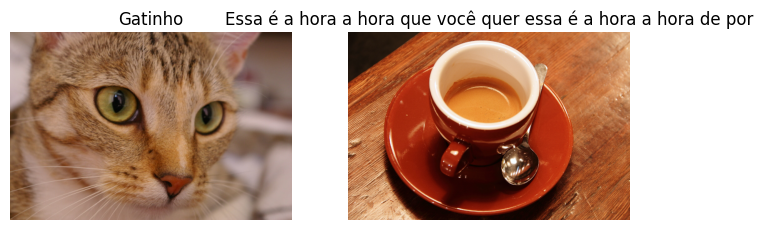

In [23]:
mostrar([data.cat(),data.coffee()],['Gatinho','Essa é a hora a hora que você quer essa é a hora a hora de por'])

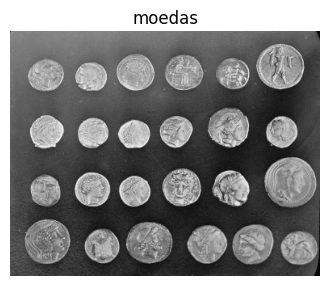

In [102]:
moedas = data.coins()
mostrar([moedas],['moedas'])

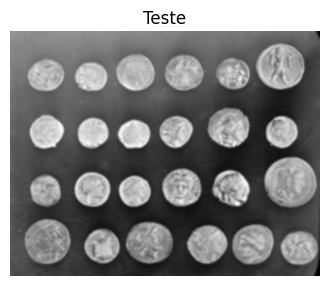

In [81]:
suave = cv2.GaussianBlur(moedas,(5,5),0)

mostrar([suave], ['Teste'])

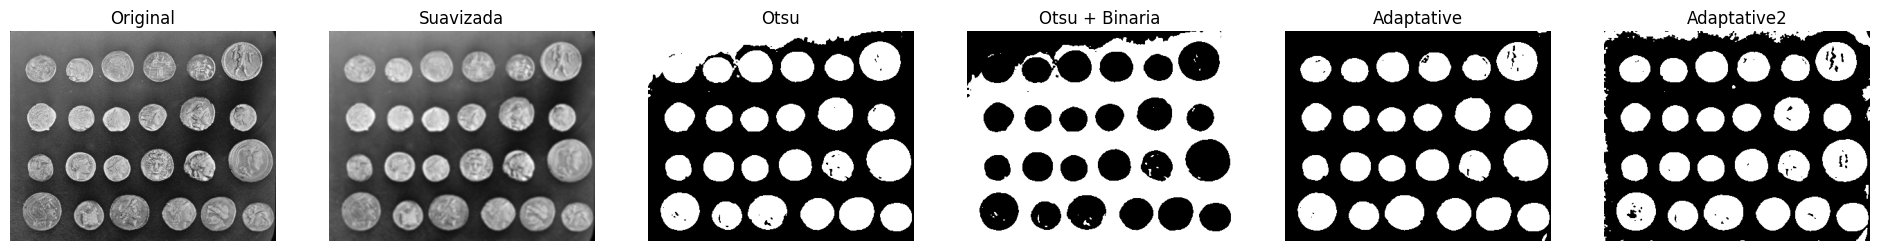

In [48]:
suave = cv2.GaussianBlur(moedas,(5,5),0)

_, mascara_otsu = cv2.threshold(suave,0, 255, cv2.THRESH_OTSU)
_, mascara_otsu2 = cv2.threshold(suave,0, 255, cv2.THRESH_OTSU + cv2.THRESH_BINARY_INV)
mascara_adapt = cv2.adaptiveThreshold(suave,255,cv2.ADAPTIVE_THRESH_MEAN_C,cv2.THRESH_BINARY,101,-20)
mascara_adapt2 = cv2.adaptiveThreshold(suave,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,101,-1)
mostrar([moedas,suave,mascara_otsu,mascara_otsu2,mascara_adapt,mascara_adapt2], ['Original', 'Suavizada', 'Otsu','Otsu + Binaria','Adaptative','Adaptative2'])

array([[[ 47,  47,  47],
        [123, 123, 123],
        [133, 133, 133],
        ...,
        [ 14,  14,  14],
        [  3,   3,   3],
        [ 12,  12,  12]],

       [[ 93,  93,  93],
        [144, 144, 144],
        [145, 145, 145],
        ...,
        [ 12,  12,  12],
        [  7,   7,   7],
        [  7,   7,   7]],

       [[126, 126, 126],
        [147, 147, 147],
        [143, 143, 143],
        ...,
        [  2,   2,   2],
        [ 13,  13,  13],
        [  3,   3,   3]],

       ...,

       [[ 81,  81,  81],
        [ 79,  79,  79],
        [ 74,  74,  74],
        ...,
        [  6,   6,   6],
        [  4,   4,   4],
        [  7,   7,   7]],

       [[ 88,  88,  88],
        [ 82,  82,  82],
        [ 74,  74,  74],
        ...,
        [  5,   5,   5],
        [  7,   7,   7],
        [  8,   8,   8]],

       [[ 91,  91,  91],
        [ 79,  79,  79],
        [ 68,  68,  68],
        ...,
        [  4,   4,   4],
        [ 10,  10,  10],
        [  7,   7,   7]]], shape=(303, 384, 3), dtype=uint8)
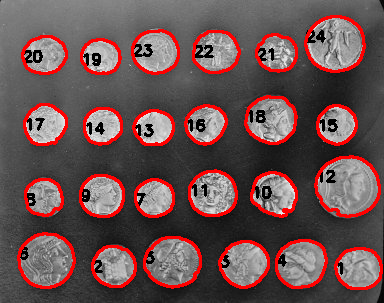

In [104]:
contornos ,_ = cv2.findContours(mascara_adapt,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

contornos = [c for c in contornos if cv2.contourArea(c) > 500]

mascara_final = np.zeros_like(mascara_adapt)


cv2.drawContours(mascara_final,contornos,-1,255, thickness= -1)

moedas_final = cv2.cvtColor(moedas,cv2.COLOR_GRAY2RGB)

cv2.drawContours(moedas_final,contornos,-1,(255,0,0), 2)

for i, c in enumerate(contornos):
  x,y,w,h = cv2.boundingRect(c)
  cv2.putText(moedas, str(i + 1),(x, y +25), cv2.FONT_HERSHEY_SIMPLEX,0.5,(0,0,0),2)#colocou verde(0,255,0)

moedas_final
